# Fig. 3 c, d: CA1 d2 vs CA3 input and vs CA2 input (BARRs) in the network model

Same simulations and style as Extended Data Fig. 8 (`FigS8_AG_network_model.ipynb`)
Spiking network model (CA3 recurrent network with short-term depression → CA1 pyramidal cells, PV and CCK interneurons), frozen sleep, 180 s per run, 5 paired seeds.
**CA3 input**: extra Poisson drive to every CA3 pyramidal cell, 0–80 Hz (maximum 80 Hz; 10, 20, 40 Hz = 2⁻³, 2⁻², 2⁻¹ × 80 Hz).
**CA2 input (BARR)**: 300-ms BARR of 50-Hz input to every CCK cell, at 0–0.5 events/s.
**d2**: distance to criticality of the pooled CA1 activity (5-ms bins, AR order 20; 30-s blocks with detected CA3 replays ± 50 ms removed).

Data: `../csv/Fig3_CD_network_model/fig3_runs.csv` (one row per run).

| panel | content | test | n |
|---|---|---|---|
| c | d2 vs CA3 drive, BARR off | Spearman ρ (runs); Friedman across drives, seeds as blocks | 30 (6 drives × 5 seeds) |
| d | d2 vs BARR rate at CA3 10, 20, 40 Hz | Spearman ρ of the paired change Δd2 (vs BARR off, same seed and drive) with BARR rate, pooled over the 3 drives; per drive: slope < 0 over seeds (one-sided t, Holm over 3) | 75 (3 drives × 5 rates × 5 seeds) |

In [1]:
import os

import matplotlib
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize
from scipy import stats

DATA = '../csv/Fig3_CD_network_model'
FIGDIR = '../figure_output/Fig3'
os.makedirs(FIGDIR, exist_ok=True)
FONTS = 'fonts'
for f in ['Regular', 'Bold']:   # Helvetica clone (Nimbus Sans), embedded as TrueType in the PDF
    if os.path.exists(f'{FONTS}/NimbusSans-{f}.ttf'):
        fm.fontManager.addfont(f'{FONTS}/NimbusSans-{f}.ttf')

runs = pd.read_csv(f'{DATA}/fig3_runs.csv')
DRIVES = sorted(runs.ca3_drive_hz.unique()); SHOW = [10.0, 20.0, 40.0]
runs.groupby(['ca3_drive_hz', 'barr_rate_hz']).size().unstack()

barr_rate_hz,0.0,0.1,0.2,0.3,0.4,0.5
ca3_drive_hz,,,,,,
0.0,5,5,5,5,5,5
5.0,5,5,5,5,5,5
10.0,5,5,5,5,5,5
20.0,5,5,5,5,5,5
40.0,5,5,5,5,5,5
80.0,5,5,5,5,5,5


In [2]:
def t_less(v):
    return stats.ttest_1samp(np.asarray(v, float), 0, alternative='less').pvalue


def holm(p):
    p = np.asarray(p, float); o = np.argsort(p); out = np.empty(len(p)); run = 0.0
    for k, i in enumerate(o):
        run = max(run, (len(p) - k) * p[i]); out[i] = min(run, 1.0)
    return out


def fp(p):
    return f'{p:.2g}' if p >= 1e-300 else '<1e-300'


ST = {}
x = runs[runs.barr_rate_hz == 0]
rho, p = stats.spearmanr(x.ca3_drive_hz, x.d2)
fr = stats.friedmanchisquare(*[g.sort_values('seed').d2.to_numpy() for _, g in x.groupby('ca3_drive_hz')])
ST['c'] = dict(rho=rho, p=p, n=len(x), chi2=fr.statistic, p_fried=fr.pvalue)

s = runs[runs.ca3_drive_hz.isin(SHOW)]
ref = s[s.barr_rate_hz == 0].set_index(['seed', 'ca3_drive_hz']).d2
s = s.assign(delta=s.d2.to_numpy() - ref.reindex(pd.MultiIndex.from_frame(s[['seed', 'ca3_drive_hz']])).to_numpy())
y = s[s.barr_rate_hz > 0]
rho, p = stats.spearmanr(y.barr_rate_hz, y.delta)
sl = s.groupby(['seed', 'ca3_drive_hz']).apply(lambda g: np.polyfit(g.barr_rate_hz, g.d2, 1)[0], include_groups=False).rename('slope').reset_index()
pd_ = {d: (sl[sl.ca3_drive_hz == d].slope.mean(), t_less(sl[sl.ca3_drive_hz == d].slope)) for d in SHOW}
ph = dict(zip(SHOW, holm([pd_[d][1] for d in SHOW])))
ST['d'] = dict(rho=rho, p=p, n=len(y), slope={d: pd_[d][0] for d in SHOW}, holm=ph)

summary = pd.DataFrame([
    {'panel': 'c', 'test': 'Spearman d2 ~ CA3 drive (BARR off)', 'stat': ST['c']['rho'], 'p': ST['c']['p'], 'n': ST['c']['n']},
    {'panel': 'c', 'test': 'Friedman across drives (seeds as blocks)', 'stat': ST['c']['chi2'], 'p': ST['c']['p_fried'], 'n': 5},
    {'panel': 'd', 'test': 'Spearman paired Δd2 ~ BARR rate, CA3 10, 20, 40 Hz pooled', 'stat': ST['d']['rho'], 'p': ST['d']['p'], 'n': ST['d']['n']},
    *[{'panel': 'd', 'test': f'BARR slope < 0 at CA3 {d:g} Hz, Holm over 3 drives', 'stat': ST['d']['slope'][d], 'p': ST['d']['holm'][d], 'n': 5} for d in SHOW],
])

## Figure
Thin grey lines: individual seeds; dots and bars: mean ± s.e.m. over the 5 seeds. Panel titles: the test of that panel (bold and *, p < 0.05). Full statistics: `fig3_statistics.csv`.

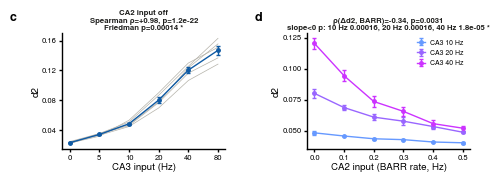

In [3]:
RC = {'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica', 'Nimbus Sans', 'Nimbus Sans TT', 'Arial'], 'font.size': 7,
      'axes.linewidth': 1, 'xtick.major.width': 1, 'ytick.major.width': 1, 'xtick.major.size': 2.5,
      'ytick.major.size': 2.5, 'pdf.fonttype': 42, 'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False}
BLACK, GREY, MUTED, BLUE = '#1f1f1d', '#b4b2a9', '#8a887f', '#0f5aa3'
CM = plt.get_cmap('cool'); DN = Normalize(0, len(DRIVES) - 1); DCOL = {d: CM(DN(k)) for k, d in enumerate(DRIVES)}
POS = {d: k for k, d in enumerate(DRIVES)}


def title(ax, text, p):
    sig = p < 0.05
    ax.set_title(text + (' *' if sig else ''), fontsize=5.6, pad=2, linespacing=1.15,
                 fontweight='bold' if sig else 'normal', color=BLACK if sig else MUTED)


def letter(ax, l):
    ax.text(-0.32, 1.08, l, transform=ax.transAxes, fontsize=9, fontweight='bold', va='bottom')


def mean_sem_line(ax, x, g, **kw):
    m, e = g.mean(), g.sem()
    ax.errorbar(x, m.values, e.values, marker='o', ms=2.5, capsize=1.5, lw=1, **kw)


with plt.rc_context(RC):
    fig = plt.figure(figsize=(4.8, 2.0))
    gs = fig.add_gridspec(1, 2, wspace=0.5, left=0.12, right=0.97, top=0.78, bottom=0.2)
    ax = {k: fig.add_subplot(gs[i]) for k, i in zip('cd', (0, 1))}

    a_ = ax['c']; x = runs[runs.barr_rate_hz == 0]
    for _, g in x.groupby('seed'):
        g = g.sort_values('ca3_drive_hz'); a_.plot([POS[d] for d in g.ca3_drive_hz], g.d2, color=GREY, lw=0.5, zorder=1)
    mean_sem_line(a_, [POS[d] for d in DRIVES], x.groupby('ca3_drive_hz').d2, color=BLUE, zorder=3)
    a_.set_xticks(range(len(DRIVES))); a_.set_xticklabels([f'{d:g}' for d in DRIVES]); a_.set_xlabel('CA3 input (Hz)', labelpad=1); a_.set_ylabel('d2', labelpad=1)
    st = ST['c']; title(a_, f"CA2 input off\nSpearman ρ={st['rho']:+.2f}, p={fp(st['p'])}\nFriedman p={fp(st['p_fried'])}", st['p'])

    a_ = ax['d']; x = runs[runs.ca3_drive_hz.isin(SHOW)]
    for d in SHOW:
        mean_sem_line(a_, sorted(x.barr_rate_hz.unique()), x[x.ca3_drive_hz == d].groupby('barr_rate_hz').d2, color=DCOL[d], label=f'CA3 {d:g} Hz')
    a_.set_xlabel('CA2 input (BARR rate, Hz)', labelpad=1); a_.set_ylabel('d2', labelpad=1); a_.legend(fontsize=5, loc='upper right', handlelength=1.2)
    st = ST['d']
    title(a_, f"ρ(Δd2, BARR)={st['rho']:+.2f}, p={fp(st['p'])}\nslope<0 p: " + ', '.join(f"{d:g} Hz {fp(st['holm'][d])}" for d in SHOW), st['p'])

    for k in 'cd':
        ax[k].tick_params(labelsize=5.5, pad=1.5); ax[k].yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(4)); letter(ax[k], k)
    fig.savefig(f'{FIGDIR}/Fig3_CD_network_model.pdf', bbox_inches='tight')
    plt.show()